# Trabajando con tablas de datos en pandas

<div style="height: 4px; background-color: #4C78A8; border-radius: 2px; margin: 0.8em 0 1.2em;"></div>

pandas es una biblioteca de Python para organizar, explorar y analizar **datos tabulares**. Podemos imaginar su estructura principal, el `DataFrame`, como una tabla en la que cada fila contiene un registro y cada columna representa una variable. A diferencia de una hoja de cálculo, las transformaciones se describen mediante código, lo que permite repetirlas y revisar cómo se ha obtenido cada resultado.

In [2]:
import sys
!{sys.executable} -m pip install pandas

  Using cached tzdata-2026.6-py2.py3-none-any.whl.metadata (1.4 kB)
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.9 MB 588.3 kB/s eta 0:00:18
   -- -------

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
from IPython.display import display

In [4]:
print(f"pandas {pd.__version__}")
print(f"NumPy {np.__version__}")

pandas 3.1.0
NumPy 2.5.2


## Series y DataFrames en pandas

Una **`Series`** contiene una secuencia de valores con etiquetas, mientras que un **`DataFrame`** organiza varias columnas sobre un índice común de filas. En términos de dimensiones, una serie tiene un eje y un DataFrame tiene dos, aunque la tabla incluya muchas variables.

### Series

Podemos pensar en una serie como la temperatura registrada en distintas fechas. Sus valores serían las temperaturas y su **índice** permitiría identificar a qué fecha corresponde cada una. Si no proporcionamos etiquetas, pandas suele crear un índice entero que empieza en cero.

Construiremos una tabla de 100 días para obtener después su columna de temperatura. Las unidades son °C para la temperatura, % para la humedad relativa, m/s para la velocidad del viento, hPa para la presión y mm para la precipitación diaria. La dirección del viento se representa mediante puntos cardinales.
<div style="padding: 0.8em 1em; margin: 1em 0; border-left: 4px solid #4C78A8; background-color: rgba(76,120,168,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.35em 0;"><strong>Datos de ejemplo.</strong> Los valores se generan de forma aleatoria y no representan observaciones ni una evolución meteorológica realista. La semilla permite reproducirlos y se introducen diez valores ausentes en temperatura y humedad para practicar su tratamiento.</p>
</div>

In [5]:
rng_tabla = np.random.default_rng(42)
fechas = pd.date_range("2022-01-01", periods=100, freq="D")
n_dias = len(fechas)

# Cada entrada del diccionario dará lugar a una columna de la tabla.
df = pd.DataFrame({
    "Fecha": fechas,
    "Temperatura": rng_tabla.uniform(15, 35, n_dias),          # °C
    "Humedad": rng_tabla.uniform(30, 90, n_dias),              # %
    "Velocidad_del_Viento": rng_tabla.uniform(0, 20, n_dias),  # m/s
    "Presion": rng_tabla.uniform(980, 1050, n_dias),           # hPa
    "Precipitaciones": rng_tabla.integers(0, 100, n_dias),     # mm diarios
    "Direccion_del_Viento": rng_tabla.choice(["N", "S", "E", "W"], n_dias),
}).set_index("Fecha")

# Sin reemplazo, las diez fechas seleccionadas son distintas.
posiciones_ausentes = rng_tabla.choice(n_dias, size=10, replace=False)
fechas_ausentes = df.index[posiciones_ausentes]
df.loc[fechas_ausentes, ["Temperatura", "Humedad"]] = np.nan

df.head()

,Temperatura,Humedad,Velocidad_del_Viento,Presion,Precipitaciones,Direccion_del_Viento
Fecha,,,,,,
2022-01-01,30.479121,84.514841,15.548097,1034.529745,1,N
2022-01-02,23.777569,71.982428,19.436529,989.418655,30,N
2022-01-03,32.171958,45.952198,10.014824,1017.524763,51,N
2022-01-04,28.947361,88.150583,2.877950,1015.995601,91,W
2022-01-05,16.883547,76.725054,0.278726,1040.030050,73,S


In [6]:
serie_temperatura = df["Temperatura"]
print(type(serie_temperatura))
serie_temperatura.head()

<class 'pandas.Series'>


Fecha
2022-01-01    30.479121
2022-01-02    23.777569
2022-01-03    32.171958
2022-01-04    28.947361
2022-01-05    16.883547
Name: Temperatura, dtype: float64

### DataFrames

Un **`DataFrame`** es una tabla bidimensional con etiquetas tanto en las filas como en las columnas. Cada columna puede tener un tipo de datos diferente, por ejemplo, números en `Temperatura` y texto en `Direccion_del_Viento`.

En nuestra tabla `df`, las fechas forman el índice. Al escribir `df["Presion"]` obtenemos una `Series` con la presión y esas mismas fechas. En cambio, `df[["Presion"]]` conserva la estructura de un DataFrame de una sola columna.

Los métodos `head()` y `tail()` permiten consultar el principio y el final de los datos sin mostrar la tabla completa. Si no indicamos otro número, devuelven cinco filas.

In [7]:
# Una etiqueta selecciona una Series con el mismo índice de fechas.
df["Presion"].head()

Fecha
2022-01-01    1034.529745
2022-01-02     989.418655
2022-01-03    1017.524763
2022-01-04    1015.995601
2022-01-05    1040.030050
Name: Presion, dtype: float64

In [8]:
df["Presion"].tail()

Fecha
2022-04-06    1011.802257
2022-04-07    1037.777966
2022-04-08    1000.675132
2022-04-09    1012.098366
2022-04-10    1010.961989
Name: Presion, dtype: float64

## Tipos de datos, valores ausentes y nombres de las columnas

### Identificación de los tipos de datos

El **tipo de datos**, o `dtype`, indica cómo se representan los valores de una columna y ayuda a interpretar qué operaciones tienen sentido. El atributo `dtypes` devuelve el tipo de cada columna del DataFrame.

| Tipo habitual | Uso |
|---|---|
| `int64` | Números enteros sin valores ausentes. |
| `float64` | Números con decimales; admite `NaN`. |
| `bool` | Valores lógicos `True` y `False`. |
| `str`, `string` u `object` | Texto, según la versión y la construcción de la columna; `object` también puede contener objetos de otros tipos. |
| `datetime64[...]` | Fechas y horas; la parte entre corchetes indica la resolución temporal. |
| `Int64` o `boolean` | Tipos de pandas que permiten enteros o booleanos con valores ausentes. |

En pandas 3.0, el texto se infiere por defecto con un tipo específico de cadenas. Por ello, una columna de texto puede mostrar un `dtype` diferente al obtenido con pandas 2.x sin que cambie el significado de sus valores.
<p style="font-size: 0.9em; margin: 0.8em 0 0.3em;"><a href="https://pandas.pydata.org/docs/whatsnew/v3.0.0.html">Tipos de texto en pandas 3.0</a></p>

In [9]:
df.dtypes

Temperatura             float64
Humedad                 float64
Velocidad_del_Viento    float64
Presion                 float64
Precipitaciones           int64
Direccion_del_Viento        str
dtype: object

### Conversión de tipos de datos

El método `astype()` permite convertir los valores de una columna a otro tipo compatible. En este ejemplo, `Precipitaciones` pasa de enteros a `float64`, un formato que admite decimales. La conversión no cambia las unidades ni añade precisión a los datos originales.

`astype()` devuelve un resultado nuevo. Para conservarlo en la tabla, lo asignamos de nuevo a la columna correspondiente.

In [10]:
# El resultado de la conversión sustituye únicamente esta columna.
df["Precipitaciones"] = df["Precipitaciones"].astype("float64")
df.dtypes

Temperatura             float64
Humedad                 float64
Velocidad_del_Viento    float64
Presion                 float64
Precipitaciones         float64
Direccion_del_Viento        str
dtype: object

### Tratamiento de datos ausentes

Un dato ausente indica que no disponemos de un valor, no que la variable valga cero. Según el tipo de columna, pandas puede representarlo mediante `NaN`, `pd.NA` o `NaT`, este último para fechas y tiempos. El método **`isna()`** permite detectarlos sin depender de su representación.

Una máscara booleana contiene `True` donde se cumple una condición y `False` en los demás casos. Al sumar la máscara producida por `isna()`, contamos los valores ausentes porque `True` contribuye como uno y `False` como cero.

* **Eliminar filas con datos ausentes**. `dropna(subset=["Humedad"])` devuelve únicamente las filas con humedad disponible. La selección de `subset` es importante porque evita descartar un registro por un dato ausente en otra variable.

En el ejemplo conservamos `df` y guardamos el resultado en `df_sin_humedad_ausente`. Por defecto, `dropna()` no modifica el objeto original.
<p style="font-size: 0.9em; margin: 0.8em 0 0.3em;"><a href="https://pandas.pydata.org/docs/user_guide/missing_data.html">Valores ausentes en pandas</a></p>

In [11]:
numero_ausentes = df["Humedad"].isna().sum()
print(f"Valores de humedad ausentes en df = {numero_ausentes}")

df_sin_humedad_ausente = df.dropna(subset=["Humedad"])
print(f"Filas conservadas = {len(df_sin_humedad_ausente)} de {len(df)}")
print(f"Valores ausentes en el resultado = {df_sin_humedad_ausente['Humedad'].isna().sum()}")
df_sin_humedad_ausente.head()

Valores de humedad ausentes en df = 10
Filas conservadas = 90 de 100
Valores ausentes en el resultado = 0


,Temperatura,Humedad,Velocidad_del_Viento,Presion,Precipitaciones,Direccion_del_Viento
Fecha,,,,,,
2022-01-01,30.479121,84.514841,15.548097,1034.529745,1.0,N
2022-01-02,23.777569,71.982428,19.436529,989.418655,30.0,N
2022-01-03,32.171958,45.952198,10.014824,1017.524763,51.0,N
2022-01-04,28.947361,88.150583,2.877950,1015.995601,91.0,W
2022-01-05,16.883547,76.725054,0.278726,1040.030050,73.0,S


* **Sustituir valores ausentes**. `fillna()` permite rellenarlos con un valor elegido o calculado. Aquí utilizamos la media de la humedad disponible en una copia de la tabla para observar el mecanismo sin alterar `df`.

<div style="padding: 0.8em 1em; margin: 1em 0; border-left: 4px solid #C58B27; background-color: rgba(197,139,39,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.35em 0;"><strong>Rellenar no equivale a observar.</strong> La imputación con la media es una demostración del método, no una recomendación general para series meteorológicas. Puede alterar la variabilidad y las relaciones entre variables. Un código como <code>-999</code> tampoco es una humedad válida y contaminaría los cálculos si no se interpretara como dato ausente.</p>
</div>

In [12]:
# La media omite los valores ausentes por defecto.
media_humedad = df["Humedad"].mean()
df_humedad_rellenada = df.copy()
df_humedad_rellenada["Humedad"] = df_humedad_rellenada["Humedad"].fillna(media_humedad)

# Comparamos solo las fechas en las que faltaba la humedad.
pd.DataFrame({
    "Humedad_original_pct": df.loc[fechas_ausentes, "Humedad"],
    "Humedad_imputada_pct": df_humedad_rellenada.loc[fechas_ausentes, "Humedad"],
}).sort_index()

,Humedad_original_pct,Humedad_imputada_pct
Fecha,,
2022-01-13,NaN,60.104166
2022-02-19,NaN,60.104166
2022-02-21,NaN,60.104166
2022-02-22,NaN,60.104166
2022-03-09,NaN,60.104166
2022-03-14,NaN,60.104166
2022-03-15,NaN,60.104166
2022-03-24,NaN,60.104166
2022-03-25,NaN,60.104166


### Nombres de las columnas

El atributo `columns` contiene las etiquetas de las columnas en un objeto `Index`. Para trabajar con una lista convencional de Python podemos convertirlo mediante `list(df.columns)`. Esta conversión cambia el contenedor de los nombres, no el DataFrame.

In [13]:
nombres_columnas = df.columns
lista_nombres_columnas = list(nombres_columnas)
print(nombres_columnas)
print(lista_nombres_columnas)

Index(['Temperatura', 'Humedad', 'Velocidad_del_Viento', 'Presion',
       'Precipitaciones', 'Direccion_del_Viento'],
      dtype='str')
['Temperatura', 'Humedad', 'Velocidad_del_Viento', 'Presion', 'Precipitaciones', 'Direccion_del_Viento']


#### Renombrar columnas

`rename(columns={"nombre_actual": "nombre_nuevo"})` cambia las etiquetas indicadas en el diccionario y conserva las demás. Renombraremos `Precipitaciones` como `Precipitacion` en un objeto nuevo para no modificar los ejemplos posteriores que utilizan `df`.

In [14]:
df_renombrado = df.rename(columns={"Precipitaciones": "Precipitacion"})
df_renombrado[["Precipitacion"]].head()

,Precipitacion
Fecha,
2022-01-01,1.0
2022-01-02,30.0
2022-01-03,51.0
2022-01-04,91.0
2022-01-05,73.0


El **nombre del índice** describe el eje, pero no es una etiqueta de fila ni una columna de datos. Por ejemplo, el índice puede llamarse `Fecha` y contener etiquetas como `2022-01-01`. El método `rename_axis()` permite cambiar ese nombre sin alterar las fechas ni las columnas.

In [15]:
df_con_nombre_indice = df.rename_axis("Fecha_de_observacion")
print(f"Nombre original del índice = {df.index.name}")
print(f"Nombre del índice en la nueva tabla = {df_con_nombre_indice.index.name}")
df_con_nombre_indice.head()

Nombre original del índice = Fecha
Nombre del índice en la nueva tabla = Fecha_de_observacion


,Temperatura,Humedad,Velocidad_del_Viento,Presion,Precipitaciones,Direccion_del_Viento
Fecha_de_observacion,,,,,,
2022-01-01,30.479121,84.514841,15.548097,1034.529745,1.0,N
2022-01-02,23.777569,71.982428,19.436529,989.418655,30.0,N
2022-01-03,32.171958,45.952198,10.014824,1017.524763,51.0,N
2022-01-04,28.947361,88.150583,2.877950,1015.995601,91.0,W
2022-01-05,16.883547,76.725054,0.278726,1040.030050,73.0,S


## El índice de filas

El **índice** es el conjunto de etiquetas que identifica las filas de una tabla. No es una columna ordinaria ni una `Series` adicional. En nuestro ejemplo, `df.index` contiene las fechas y `df.columns` contiene los nombres de las variables.

Las etiquetas pueden ser números, texto, fechas o combinaciones de varios niveles. No tienen que ser únicas, aunque los duplicados pueden hacer que una selección devuelva más de una fila. Podemos comprobarlo con `df.index.is_unique`.

Las etiquetas de un objeto `Index` no se cambian elemento a elemento, pero sí es posible sustituir el índice completo o utilizar operaciones que construyen uno nuevo. Además de facilitar las selecciones, el índice interviene en la **alineación automática** de los datos. Al operar con dos series, pandas relaciona sus etiquetas, no necesariamente sus posiciones.

### Configuración de un índice

`set_index("Fecha")` convierte una columna existente en el índice de filas y, por defecto, la retira de las columnas de datos. Como `df` ya utiliza fechas en su índice, primero creamos una tabla con esa fecha como columna mediante `reset_index()`. Así podemos practicar la operación sin intentar seleccionar una columna que ya no existe.
<div style="padding: 0.8em 1em; margin: 1em 0; border-left: 4px solid #59A14F; background-color: rgba(89,161,79,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.35em 0;"><strong>Etiqueta y posición.</strong> La etiqueta de una fila puede ser el número <code>10</code> sin ocupar la posición diez. Esta distinción será esencial al utilizar <code>loc</code> e <code>iloc</code>.</p>
</div>

In [16]:
# Recuperamos la fecha como columna para demostrar set_index().
df_con_fecha = df.reset_index()
df_indice_fechas = df_con_fecha.set_index("Fecha")
display(df_con_fecha.head())
display(df_indice_fechas.head())

,Fecha,Temperatura,Humedad,Velocidad_del_Viento,Presion,Precipitaciones,Direccion_del_Viento
0,2022-01-01,30.479121,84.514841,15.548097,1034.529745,1.0,N
1,2022-01-02,23.777569,71.982428,19.436529,989.418655,30.0,N
2,2022-01-03,32.171958,45.952198,10.014824,1017.524763,51.0,N
3,2022-01-04,28.947361,88.150583,2.877950,1015.995601,91.0,W
4,2022-01-05,16.883547,76.725054,0.278726,1040.030050,73.0,S


,Temperatura,Humedad,Velocidad_del_Viento,Presion,Precipitaciones,Direccion_del_Viento
Fecha,,,,,,
2022-01-01,30.479121,84.514841,15.548097,1034.529745,1.0,N
2022-01-02,23.777569,71.982428,19.436529,989.418655,30.0,N
2022-01-03,32.171958,45.952198,10.014824,1017.524763,51.0,N
2022-01-04,28.947361,88.150583,2.877950,1015.995601,91.0,W
2022-01-05,16.883547,76.725054,0.278726,1040.030050,73.0,S


`reset_index()` crea un índice entero consecutivo y, por defecto, conserva las antiguas etiquetas como una columna. Con `drop=True`, esas etiquetas no pasan a las columnas del resultado.

Comparamos ambas opciones a partir de la misma tabla, guardando cada resultado por separado. De este modo, no confundimos el efecto de una operación con el de otra ejecutada previamente. Después recuperamos el índice de fechas usando la versión que las conserva.

In [15]:
df_indice_numerico = df_indice_fechas.reset_index()
df_sin_fechas = df_indice_fechas.reset_index(drop=True)

print("Resultado que conserva las fechas como columna")
display(df_indice_numerico.head())
print("Resultado que descarta las etiquetas de fecha")
display(df_sin_fechas.head())

Resultado que conserva las fechas como columna


,Fecha,Temperatura,Humedad,Velocidad_del_Viento,Presion,Precipitaciones,Direccion_del_Viento
0,2022-01-01,30.479121,84.514841,15.548097,1034.529745,1.0,N
1,2022-01-02,23.777569,71.982428,19.436529,989.418655,30.0,N
2,2022-01-03,32.171958,45.952198,10.014824,1017.524763,51.0,N
3,2022-01-04,28.947361,88.150583,2.877950,1015.995601,91.0,W
4,2022-01-05,16.883547,76.725054,0.278726,1040.030050,73.0,S


Resultado que descarta las etiquetas de fecha


,Temperatura,Humedad,Velocidad_del_Viento,Presion,Precipitaciones,Direccion_del_Viento
0,30.479121,84.514841,15.548097,1034.529745,1.0,N
1,23.777569,71.982428,19.436529,989.418655,30.0,N
2,32.171958,45.952198,10.014824,1017.524763,51.0,N
3,28.947361,88.150583,2.877950,1015.995601,91.0,W
4,16.883547,76.725054,0.278726,1040.030050,73.0,S


In [16]:
# Solo la versión que conserva Fecha permite recuperar ese índice.
df_reindexado = df_indice_numerico.set_index("Fecha")
print(f"Se ha recuperado la tabla con índice temporal = {df_reindexado.equals(df)}")
df_reindexado.head()

Se ha recuperado la tabla con índice temporal = True


,Temperatura,Humedad,Velocidad_del_Viento,Presion,Precipitaciones,Direccion_del_Viento
Fecha,,,,,,
2022-01-01,30.479121,84.514841,15.548097,1034.529745,1.0,N
2022-01-02,23.777569,71.982428,19.436529,989.418655,30.0,N
2022-01-03,32.171958,45.952198,10.014824,1017.524763,51.0,N
2022-01-04,28.947361,88.150583,2.877950,1015.995601,91.0,W
2022-01-05,16.883547,76.725054,0.278726,1040.030050,73.0,S


Para reemplazar determinadas etiquetas de fila podemos utilizar `rename(index={...})`. Aunque el resultado muestre algunas etiquetas distintas, la operación construye un índice con esos cambios en lugar de modificar una de sus posiciones directamente.

En esta tabla independiente sustituiremos `a` por `AB` y `c` por `CD`. Al no utilizar `inplace=True`, conservamos también la tabla anterior. Los métodos que admiten `inplace=True` modifican el objeto sobre el que se llaman y habitualmente devuelven `None`, por lo que no debe asignarse ese retorno como si fuera una tabla.

In [17]:
df_ejemplo = pd.DataFrame(
    {"Columna1": [1, 2, 3, 4], "Columna2": [5, 6, 7, 8]},
    index=["a", "b", "c", "d"],
)
df_etiquetas_nuevas = df_ejemplo.rename(index={"a": "AB", "c": "CD"})
display(df_ejemplo)
display(df_etiquetas_nuevas)

,Columna1,Columna2
a,1,5
b,2,6
c,3,7
d,4,8


,Columna1,Columna2
AB,1,5
b,2,6
CD,3,7
d,4,8


## Seleccionar subconjuntos de datos

Seleccionar consiste en conservar solo las filas o columnas que necesitamos, por ejemplo, una variable, un periodo o los registros que cumplen una condición.

### Seleccionar columnas

La forma más general de obtener una columna es `df["Temperatura"]`. La notación `df.Temperatura` también funciona cuando el nombre es un identificador válido y no coincide con un atributo de pandas, pero no sirve para todos los nombres. Por ello, utilizaremos preferentemente corchetes.

Una etiqueta devuelve una `Series`, mientras que una lista de etiquetas, incluso con un solo elemento, devuelve un `DataFrame`.

In [18]:
temperaturas_col = df["Temperatura"]
temperaturas_punto = df.Temperatura
temperaturas_tabla = df[["Temperatura"]]

print(f"Una etiqueta produce {type(temperaturas_col).__name__}")
print(f"Una lista de etiquetas produce {type(temperaturas_tabla).__name__}")
print(f"Corchetes y notación de punto coinciden = {temperaturas_col.equals(temperaturas_punto)}")
display(temperaturas_col.head())
display(temperaturas_tabla.head())

Una etiqueta produce Series
Una lista de etiquetas produce DataFrame
Corchetes y notación de punto coinciden = True


Fecha
2022-01-01    30.479121
2022-01-02    23.777569
2022-01-03    32.171958
2022-01-04    28.947361
2022-01-05    16.883547
Name: Temperatura, dtype: float64

,Temperatura
Fecha,
2022-01-01,30.479121
2022-01-02,23.777569
2022-01-03,32.171958
2022-01-04,28.947361
2022-01-05,16.883547


### Seleccionar filas por posición o etiqueta

**`iloc` trabaja con posiciones enteras**, contadas desde cero. **`loc` trabaja con etiquetas**, como las fechas del índice. Ninguno de los dos es un método al que se llame con paréntesis; la selección se escribe entre corchetes.

En nuestro ejemplo, `df.iloc[0]` y `df.loc["2022-01-01"]` seleccionan la misma fila por caminos diferentes. Si cambiara el orden de la tabla, la primera posición podría corresponder a otra fecha.

In [19]:
primera_fila = df.iloc[0]
primera_fila

Temperatura               30.479121
Humedad                   84.514841
Velocidad_del_Viento      15.548097
Presion                 1034.529745
Precipitaciones                 1.0
Direccion_del_Viento              N
Name: 2022-01-01 00:00:00, dtype: object

In [20]:
# Fecha ya es el índice; no hay que volver a llamar a set_index().
fila_por_etiqueta = df.loc["2022-01-01"]
fila_por_etiqueta

Temperatura               30.479121
Humedad                   84.514841
Velocidad_del_Viento      15.548097
Presion                 1034.529745
Precipitaciones                 1.0
Direccion_del_Viento              N
Name: 2022-01-01 00:00:00, dtype: object

### Seleccionar rangos

La forma `df.iloc[filas, columnas]` permite elegir posiciones en ambos ejes. Un corte `inicio:fin:paso` incluye el inicio y excluye el final, como en las listas de Python. Por ejemplo, `0:8:2` selecciona las posiciones 0, 2, 4 y 6.

Los dos puntos por sí solos, `:`, indican que se conserva todo ese eje. También podemos proporcionar listas de posiciones que no sean consecutivas.

In [21]:
# Cinco filas y las columnas que ocupan las posiciones 2 y 3.
subconjunto_filas_columnas = df.iloc[0:5, 2:4]
display(subconjunto_filas_columnas)

# Las posiciones de fila seleccionadas son 0, 2, 4 y 6.
subconjunto_saltos = df.iloc[0:8:2, 2:4]
display(subconjunto_saltos)

subconjunto_discontinuo = df.iloc[[0, 3, 7], [1, 4]]
display(subconjunto_discontinuo)

# Los dos puntos conservan todas las columnas de la primera fila.
display(df.iloc[0, :])

,Velocidad_del_Viento,Presion
Fecha,,
2022-01-01,15.548097,1034.529745
2022-01-02,19.436529,989.418655
2022-01-03,10.014824,1017.524763
2022-01-04,2.877950,1015.995601
2022-01-05,0.278726,1040.030050


,Velocidad_del_Viento,Presion
Fecha,,
2022-01-01,15.548097,1034.529745
2022-01-03,10.014824,1017.524763
2022-01-05,0.278726,1040.030050
2022-01-07,2.636444,1006.956265


,Humedad,Precipitaciones
Fecha,,
2022-01-01,84.514841,1.0
2022-01-04,88.150583,91.0
2022-01-08,46.334494,11.0


Temperatura               30.479121
Humedad                   84.514841
Velocidad_del_Viento      15.548097
Presion                 1034.529745
Precipitaciones                 1.0
Direccion_del_Viento              N
Name: 2022-01-01 00:00:00, dtype: object

Con `loc` utilizamos etiquetas tanto para las filas como para las columnas. Una lista selecciona etiquetas concretas, mientras que un corte permite seleccionar un intervalo en un índice ordenado.

<div style="padding: 0.8em 1em; margin: 1em 0; border-left: 4px solid #59A14F; background-color: rgba(89,161,79,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.35em 0;"><strong>Los extremos no se tratan igual.</strong> En <code>iloc[0:5]</code> no se incluye la posición 5. En el corte de fechas <code>loc["2022-01-01":"2022-01-05"]</code> se incluyen ambos días. Nuestro índice está ordenado cronológicamente.</p>
</div>

<p style="font-size: 0.9em; margin: 0.8em 0 0.3em;"><a href="https://pandas.pydata.org/docs/user_guide/indexing.html">Selección por etiquetas y posiciones</a></p>

In [22]:
fila_etiqueta = df.loc["2022-01-01", :]
subconjunto_etiquetas = df.loc[
    ["2022-01-01", "2022-01-15"], ["Temperatura", "Humedad"]
]
rango_etiquetas = df.loc["2022-01-01":"2022-01-05", ["Temperatura", "Humedad"]]

display(fila_etiqueta)
display(subconjunto_etiquetas)
display(rango_etiquetas)

Temperatura               30.479121
Humedad                   84.514841
Velocidad_del_Viento      15.548097
Presion                 1034.529745
Precipitaciones                 1.0
Direccion_del_Viento              N
Name: 2022-01-01 00:00:00, dtype: object

,Temperatura,Humedad
Fecha,,
2022-01-01,30.479121,84.514841
2022-01-15,23.868284,40.606367


,Temperatura,Humedad
Fecha,,
2022-01-01,30.479121,84.514841
2022-01-02,23.777569,71.982428
2022-01-03,32.171958,45.952198
2022-01-04,28.947361,88.150583
2022-01-05,16.883547,76.725054


### Filtrar datos con condiciones

Una comparación como `df["Temperatura"] > 25` produce una **máscara booleana** con la que podemos seleccionar las filas que cumplen la condición. El umbral de 25 °C es ilustrativo y no define por sí mismo un episodio meteorológico.

Para combinar condiciones elemento a elemento utilizamos `&` como «y», `|` como «o» y `~` para negar una máscara. Cada comparación debe ir entre paréntesis. Los operadores `and` y `or` de Python no sustituyen a `&` y `|` en estas selecciones.

Con los valores `NaN` de este ejemplo, las comparaciones de temperatura no se cumplen y esas filas quedan fuera de la selección.

In [23]:
mascara_calor = df["Temperatura"] > 25
filas_filtradas = df.loc[mascara_calor]

# Ambas comparaciones deben cumplirse en la misma fila.
mascara_intervalo = (df["Temperatura"] > 20) & (df["Temperatura"] < 25)
filas_varias_condiciones = df.loc[mascara_intervalo]

print(f"Registros con temperatura superior a 25 °C = {len(filas_filtradas)}")
display(filas_filtradas.head())
print(f"Registros entre 20 y 25 °C, sin incluir extremos = {len(filas_varias_condiciones)}")
display(filas_varias_condiciones.head())

Registros con temperatura superior a 25 °C = 43


,Temperatura,Humedad,Velocidad_del_Viento,Presion,Precipitaciones,Direccion_del_Viento
Fecha,,,,,,
2022-01-01,30.479121,84.514841,15.548097,1034.529745,1.0,N
2022-01-03,32.171958,45.952198,10.014824,1017.524763,51.0,N
2022-01-04,28.947361,88.150583,2.877950,1015.995601,91.0,W
2022-01-06,34.512447,73.013411,4.593121,1012.395956,78.0,E
2022-01-07,30.222794,56.961690,2.636444,1006.956265,54.0,S


Registros entre 20 y 25 °C, sin incluir extremos = 26


,Temperatura,Humedad,Velocidad_del_Viento,Presion,Precipitaciones,Direccion_del_Viento
Fecha,,,,,,
2022-01-02,23.777569,71.982428,19.436529,989.418655,30.0,N
2022-01-10,24.007719,84.156144,10.126599,989.783789,99.0,N
2022-01-11,22.415960,57.346577,13.885249,1013.451409,4.0,W
2022-01-15,23.868284,40.606367,14.308143,1005.647471,77.0,E
2022-01-22,22.090519,68.990796,9.771681,1013.663730,66.0,E


También podemos seleccionar una sola variable con **`df.loc[mascara, "columna"]`**. Así indicamos en una misma operación qué filas y qué columna nos interesan, en lugar de encadenar selecciones.

Este patrón resulta especialmente importante al modificar datos. Para cambiar el DataFrame original se utiliza, por ejemplo, `df.loc[mascara, "columna"] = valor`. Para transformar un subconjunto por separado, podemos obtenerlo con `.copy()` y asignarle otro nombre.
<p style="font-size: 0.9em; margin: 0.8em 0 0.3em;"><a href="https://pandas.pydata.org/docs/whatsnew/v3.0.0.html">Asignación y Copy-on-Write</a></p>

In [24]:
filas_filtradas_temperatura = df.loc[mascara_calor, "Temperatura"]
filas_condiciones_temperatura = df.loc[mascara_intervalo, "Temperatura"]
display(filas_filtradas_temperatura.head())
display(filas_condiciones_temperatura.head())

# Una copia permite transformar el subconjunto sin cambiar df.
df_temperaturas_seleccionadas = df.loc[mascara_calor, ["Temperatura"]].copy()
df_temperaturas_seleccionadas["Temperatura_K"] = (
    df_temperaturas_seleccionadas["Temperatura"] + 273.15
)
df_temperaturas_seleccionadas.head()

Fecha
2022-01-01    30.479121
2022-01-03    32.171958
2022-01-04    28.947361
2022-01-06    34.512447
2022-01-07    30.222794
Name: Temperatura, dtype: float64

Fecha
2022-01-02    23.777569
2022-01-10    24.007719
2022-01-11    22.415960
2022-01-15    23.868284
2022-01-22    22.090519
Name: Temperatura, dtype: float64

,Temperatura,Temperatura_K
Fecha,,
2022-01-01,30.479121,303.629121
2022-01-03,32.171958,305.321958
2022-01-04,28.947361,302.097361
2022-01-06,34.512447,307.662447
2022-01-07,30.222794,303.372794


## Concatenar y fusionar DataFrames

Combinar tablas puede significar **añadir registros o variables**, o bien **relacionar registros mediante una clave común**. `pd.concat()` resuelve el primer caso y `pd.merge()` el segundo.

### Concatenar

`pd.concat()` coloca varios objetos a continuación de otros sobre el eje elegido. Con `axis=0` añade filas y alinea los nombres de las columnas. Con `axis=1` añade columnas y alinea las etiquetas de las filas. La alineación no se hace por la posición que ocupan los datos.

Los cuatro ejemplos siguientes combinan columnas comunes o distintas con índices comunes o distintos. Cuando falta una correspondencia aparecen valores ausentes. La concatenación conserva las etiquetas salvo que indiquemos lo contrario, por lo que puede producir filas o columnas con nombres repetidos.

<div style="padding: 0.8em 1em; margin: 1em 0; border-left: 4px solid #C58B27; background-color: rgba(197,139,39,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.35em 0;"><strong>Código de versiones anteriores.</strong> <code>DataFrame.append()</code> se retiró en pandas 2.0. Para añadir filas se utiliza <code>pd.concat()</code>; si partimos de un diccionario, primero lo convertimos en un DataFrame de una fila.</p>
</div>

<p style="font-size: 0.9em; margin: 0.8em 0 0.3em;"><a href="https://pandas.pydata.org/docs/user_guide/merging.html">Concatenación y unión de tablas</a></p>
<p style="font-size: 0.9em; margin: 0.8em 0 0.3em;"><a href="https://pandas.pydata.org/docs/whatsnew/v2.0.0.html">Retirada de append en pandas 2.0</a></p>

In [25]:
# Caso 1 · Columnas comunes e índices distintos
df1 = pd.DataFrame(
    {"A": ["A0", "A1", "A2"], "B": ["B0", "B1", "B2"]},
    index=[0, 1, 2],
)
df2 = pd.DataFrame(
    {"A": ["A3", "A4", "A5"], "B": ["B3", "B4", "B5"]},
    index=[3, 4, 5],
)

concatenado_filas = pd.concat([df1, df2], axis=0)
concatenado_columnas = pd.concat([df1, df2], axis=1)
print("Añadimos filas y alineamos columnas")
display(concatenado_filas)
print("Añadimos columnas y alineamos filas")
display(concatenado_columnas)

Añadimos filas y alineamos columnas


,A,B
0,A0,B0
1,A1,B1
2,A2,B2
3,A3,B3
4,A4,B4
5,A5,B5


Añadimos columnas y alineamos filas


,A,B,A,B
0,A0,B0,NaN,NaN
1,A1,B1,NaN,NaN
2,A2,B2,NaN,NaN
3,NaN,NaN,A3,B3
4,NaN,NaN,A4,B4
5,NaN,NaN,A5,B5


In [26]:
# Caso 2 · Columnas distintas e índices distintos
df1 = pd.DataFrame(
    {"A": ["A0", "A1", "A2"], "B": ["B0", "B1", "B2"]},
    index=[0, 1, 2],
)
df2 = pd.DataFrame(
    {"C": ["C3", "C4", "C5"], "D": ["D3", "D4", "D5"]},
    index=[3, 4, 5],
)

concatenado_filas = pd.concat([df1, df2], axis=0)
concatenado_columnas = pd.concat([df1, df2], axis=1)
print("Añadimos filas y alineamos columnas")
display(concatenado_filas)
print("Añadimos columnas y alineamos filas")
display(concatenado_columnas)

Añadimos filas y alineamos columnas


,A,B,C,D
0,A0,B0,NaN,NaN
1,A1,B1,NaN,NaN
2,A2,B2,NaN,NaN
3,NaN,NaN,C3,D3
4,NaN,NaN,C4,D4
5,NaN,NaN,C5,D5


Añadimos columnas y alineamos filas


,A,B,C,D
0,A0,B0,NaN,NaN
1,A1,B1,NaN,NaN
2,A2,B2,NaN,NaN
3,NaN,NaN,C3,D3
4,NaN,NaN,C4,D4
5,NaN,NaN,C5,D5


In [27]:
# Caso 3 · Columnas comunes e índices comunes
df1 = pd.DataFrame(
    {"A": ["A0", "A1", "A2"], "B": ["B0", "B1", "B2"]},
    index=[0, 1, 2],
)
df2 = pd.DataFrame(
    {"A": ["A3", "A4", "A5"], "B": ["B3", "B4", "B5"]},
    index=[0, 1, 2],
)

concatenado_filas = pd.concat([df1, df2], axis=0)
concatenado_columnas = pd.concat([df1, df2], axis=1)
print("Añadimos filas y alineamos columnas")
display(concatenado_filas)
print("Añadimos columnas y alineamos filas")
display(concatenado_columnas)

Añadimos filas y alineamos columnas


,A,B
0,A0,B0
1,A1,B1
2,A2,B2
0,A3,B3
1,A4,B4
2,A5,B5


Añadimos columnas y alineamos filas


,A,B,A,B
0,A0,B0,A3,B3
1,A1,B1,A4,B4
2,A2,B2,A5,B5


In [28]:
# Caso 4 · Columnas distintas e índices comunes
df1 = pd.DataFrame(
    {"A": ["A0", "A1", "A2"], "B": ["B0", "B1", "B2"]},
    index=[0, 1, 2],
)
df2 = pd.DataFrame(
    {"C": ["C3", "C4", "C5"], "D": ["D3", "D4", "D5"]},
    index=[0, 1, 2],
)

concatenado_filas = pd.concat([df1, df2], axis=0)
concatenado_columnas = pd.concat([df1, df2], axis=1)
print("Añadimos filas y alineamos columnas")
display(concatenado_filas)
print("Añadimos columnas y alineamos filas")
display(concatenado_columnas)

Añadimos filas y alineamos columnas


,A,B,C,D
0,A0,B0,NaN,NaN
1,A1,B1,NaN,NaN
2,A2,B2,NaN,NaN
0,NaN,NaN,C3,D3
1,NaN,NaN,C4,D4
2,NaN,NaN,C5,D5


Añadimos columnas y alineamos filas


,A,B,C,D
0,A0,B0,C3,D3
1,A1,B1,C4,D4
2,A2,B2,C5,D5


`pd.concat()` permite controlar la alineación y las etiquetas del resultado. Una llamada con varias de sus opciones sería la siguiente.

```python
pd.concat([df1, df2], axis=0, join="outer", ignore_index=False, keys=None, sort=False)
```

Los próximos ejemplos recuperan las dos tablas del cuarto caso, que tienen el mismo índice y columnas distintas.

#### `join`

`join` actúa sobre el **eje que no se concatena**. Al añadir filas, `join="outer"` conserva todas las columnas y `join="inner"` solo las comunes. Al añadir columnas, esas mismas opciones se aplican a las etiquetas de las filas.

En nuestras tablas las columnas son distintas, por lo que la concatenación vertical con `join="inner"` no conserva ninguna columna. Es un resultado esperado, no un error.

In [29]:
resultado_outer = pd.concat([df1, df2], axis=0, join="outer")
resultado_inner = pd.concat([df1, df2], axis=0, join="inner")
display(resultado_outer)
display(resultado_inner)
print(f"Forma del resultado inner = {resultado_inner.shape}")

,A,B,C,D
0,A0,B0,NaN,NaN
1,A1,B1,NaN,NaN
2,A2,B2,NaN,NaN
0,NaN,NaN,C3,D3
1,NaN,NaN,C4,D4
2,NaN,NaN,C5,D5


""
0
1
2
0
1
2


Forma del resultado inner = (6, 0)


#### `ignore_index`

Con `ignore_index=True`, las etiquetas del eje concatenado se sustituyen por una secuencia de enteros que empieza en cero. Al añadir filas, esto crea un nuevo índice de filas, pero no elimina registros duplicados ni modifica la alineación de las columnas.

In [30]:
resultado_indice_nuevo = pd.concat([df1, df2], ignore_index=True)
resultado_indice_original = pd.concat([df1, df2], ignore_index=False)
display(resultado_indice_nuevo)
display(resultado_indice_original)

,A,B,C,D
0,A0,B0,NaN,NaN
1,A1,B1,NaN,NaN
2,A2,B2,NaN,NaN
3,NaN,NaN,C3,D3
4,NaN,NaN,C4,D4
5,NaN,NaN,C5,D5


,A,B,C,D
0,A0,B0,NaN,NaN
1,A1,B1,NaN,NaN
2,A2,B2,NaN,NaN
0,NaN,NaN,C3,D3
1,NaN,NaN,C4,D4
2,NaN,NaN,C5,D5


#### `keys`

`keys` añade etiquetas que permiten identificar de qué tabla procede cada bloque. El resultado utiliza un **índice jerárquico**, o `MultiIndex`, formado por varios niveles.

Con `axis=0`, los niveles se incorporan al índice de filas; con `axis=1`, a las columnas. Una tupla como `("x", 0)` identifica la etiqueta `x` del primer nivel y la etiqueta `0` del segundo. Las tuplas con tres elementos siguen la misma idea para tres niveles.

In [31]:
resultado1 = pd.concat([df1, df2], keys=["x", "y"], names=["Origen", "Fila"])
display(resultado1)

# Una etiqueta selecciona un bloque; una tupla selecciona una fila de ese bloque.
display(resultado1.loc["x"])
display(resultado1.loc[("x", 0), :])

A    B    C    D
Origen Fila                    
x      0      A0   B0  NaN  NaN
       1      A1   B1  NaN  NaN
       2      A2   B2  NaN  NaN
y      0     NaN  NaN   C3   D3
       1     NaN  NaN   C4   D4
       2     NaN  NaN   C5   D5

,A,B,C,D
Fila,,,,
0,A0,B0,NaN,NaN
1,A1,B1,NaN,NaN
2,A2,B2,NaN,NaN


A     A0
B     B0
C    NaN
D    NaN
Name: (x, 0), dtype: object

In [32]:
resultado2 = pd.concat(
    [df1, df2], axis=1, keys=["x", "y"], names=["Origen", "Variable"]
)
display(resultado2)
display(resultado2["x"])

# La tupla identifica una columna en sus dos niveles.
display(resultado2[("x", "A")])

Origen     x       y    
Variable   A   B   C   D
0         A0  B0  C3  D3
1         A1  B1  C4  D4
2         A2  B2  C5  D5

Variable,A,B
0,A0,B0
1,A1,B1
2,A2,B2


0    A0
1    A1
2    A2
Name: (x, A), dtype: object

In [33]:
resultado3 = pd.concat(
    [df1, df2, df2, df1],
    keys=[("x", "first"), ("x", "second"), ("y", "first"), ("y", "second")],
    names=["Grupo", "Bloque", "Fila"],
)
display(resultado3)
display(resultado3.loc[("x", "second", 1), :])

# Elegimos también la columna por su nombre, no por una posición implícita.
print(resultado3.loc[("x", "second", 1), "D"])

A    B    C    D
Grupo Bloque Fila                    
x     first  0      A0   B0  NaN  NaN
             1      A1   B1  NaN  NaN
             2      A2   B2  NaN  NaN
      second 0     NaN  NaN   C3   D3
             1     NaN  NaN   C4   D4
             2     NaN  NaN   C5   D5
y     first  0     NaN  NaN   C3   D3
             1     NaN  NaN   C4   D4
             2     NaN  NaN   C5   D5
      second 0      A0   B0  NaN  NaN
             1      A1   B1  NaN  NaN
             2      A2   B2  NaN  NaN

A    NaN
B    NaN
C     C4
D     D4
Name: (x, second, 1), dtype: object

D4


In [34]:
resultado4 = pd.concat(
    [df1, df2, df2, df1],
    axis=1,
    keys=[("m", "first"), ("m", "second"), ("n", "first"), ("n", "second")],
    names=["Grupo", "Bloque", "Variable"],
)
display(resultado4)
display(resultado4[("m", "first", "A")])

# La fila tiene etiqueta 2 y la columna se identifica mediante una tupla.
print(resultado4.loc[2, ("m", "second", "C")])

Grupo        m                    n               
Bloque   first     second     first     second    
Variable     A   B      C   D     C   D      A   B
0           A0  B0     C3  D3    C3  D3     A0  B0
1           A1  B1     C4  D4    C4  D4     A1  B1
2           A2  B2     C5  D5    C5  D5     A2  B2

0    A0
1    A1
2    A2
Name: (m, first, A), dtype: object

C5


#### `sort`

`sort=True` ordena las etiquetas del eje que no se concatena. Al añadir filas ordena las columnas; al añadir columnas ordena las etiquetas de fila cuando la alineación lo requiere. No ordena los registros según los valores de una variable.

Para ver el efecto sobre las columnas, partimos de dos tablas cuyos nombres no están en orden alfabético.

In [35]:
tabla_ba = df1[["B", "A"]]
tabla_dc = df2[["D", "C"]]
resultado_sin_ordenar = pd.concat([tabla_ba, tabla_dc], sort=False)
resultado_ordenado = pd.concat([tabla_ba, tabla_dc], sort=True)
display(resultado_sin_ordenar)
display(resultado_ordenado)

,B,A,D,C
0,B0,A0,NaN,NaN
1,B1,A1,NaN,NaN
2,B2,A2,NaN,NaN
0,NaN,NaN,D3,C3
1,NaN,NaN,D4,C4
2,NaN,NaN,D5,C5


,A,B,C,D
0,A0,B0,NaN,NaN
1,A1,B1,NaN,NaN
2,A2,B2,NaN,NaN
0,NaN,NaN,C3,D3
1,NaN,NaN,C4,D4
2,NaN,NaN,C5,D5


### Fusionar

`pd.merge()` relaciona filas a partir de una o varias **claves**, como el código de una estación. La clave indica qué registros corresponden entre sí, aunque estén en posiciones distintas.

```python
pd.merge(df_izq, df_der, how="inner", on="clave")
```

Antes de unir tablas conviene comprobar cuántas veces aparece cada clave. Si una clave está repetida en ambos lados, la unión genera todas las combinaciones de sus filas. `validate="one_to_one"` comprueba que las claves sean únicas en ambas tablas; `validate="many_to_one"` permite repeticiones a la izquierda, pero no a la derecha.

En estos ejemplos las claves son únicas. Los nombres `df_izq` y `df_der` indican simplemente el lado que ocupa cada tabla en la llamada.

In [36]:
df_izq = pd.DataFrame({
    "clave": ["K0", "K1", "K2", "K3"],
    "A": ["A0", "A1", "A2", "A3"],
    "B": ["B0", "B1", "B2", "B3"],
})
df_der = pd.DataFrame({
    "clave": ["K2", "K0", "K3", "K1"],
    "C": ["C2", "C0", "C3", "C1"],
    "D": ["D2", "D0", "D3", "D1"],
})

# Las claves coinciden, pero las filas no están en el mismo orden.
display(df_izq)
display(df_der)

,clave,A,B
0,K0,A0,B0
1,K1,A1,B1
2,K2,A2,B2
3,K3,A3,B3


,clave,C,D
0,K2,C2,D2
1,K0,C0,D0
2,K3,C3,D3
3,K1,C1,D1


#### `left` y `right`

Son las tablas izquierda y derecha. Normalmente se proporcionan como los dos primeros argumentos de `pd.merge()`. El orden importa, por ejemplo, cuando queremos conservar todas las filas de uno de los dos lados.

#### `on`

`on="clave"` indica que la unión se realiza mediante la columna `clave`, presente en ambas tablas. Para una clave formada por varias columnas se proporciona una lista de nombres.

Si no indicamos `on` ni otra forma de emparejamiento, pandas puede utilizar las columnas que ambas tablas tienen en común. Es preferible escribir la clave de forma explícita para evitar uniones accidentales.

In [37]:
merge_on = pd.merge(df_izq, df_der, on="clave", validate="one_to_one")
merge_on

,clave,A,B,C,D
0,K0,A0,B0,C0,D0
1,K1,A1,B1,C1,D1
2,K2,A2,B2,C2,D2
3,K3,A3,B3,C3,D3


#### `left_on` y `right_on`

Estas opciones permiten unir tablas cuyas claves tienen nombres diferentes. `left_on` identifica la columna de la izquierda y `right_on` la de la derecha. En el ejemplo renombramos la clave de la tabla derecha para que la diferencia sea visible.

In [38]:
df_der_otra_clave = df_der.rename(columns={"clave": "codigo"})
merge_left_right_on = pd.merge(
    df_izq,
    df_der_otra_clave,
    left_on="clave",
    right_on="codigo",
    validate="one_to_one",
)
merge_left_right_on

,clave,A,B,codigo,C,D
0,K0,A0,B0,K0,C0,D0
1,K1,A1,B1,K1,C1,D1
2,K2,A2,B2,K2,C2,D2
3,K3,A3,B3,K3,C3,D3


#### `left_index` y `right_index`

Con `left_index=True` y `right_index=True` utilizamos los índices como claves. Esto solo tiene sentido si sus etiquetas identifican la misma entidad en ambas tablas. Dos índices enteros consecutivos pueden coincidir sin que sus filas correspondan al mismo registro.

Para evitar esa coincidencia puramente posicional, primero establecemos `clave` como índice en ambos lados.

In [39]:
izquierda_por_clave = df_izq.set_index("clave")
derecha_por_clave = df_der.set_index("clave")
merge_indices = pd.merge(
    izquierda_por_clave,
    derecha_por_clave,
    left_index=True,
    right_index=True,
    validate="one_to_one",
)
merge_indices

,A,B,C,D
clave,,,,
K0,A0,B0,C0,D0
K1,A1,B1,C1,D1
K2,A2,B2,C2,D2
K3,A3,B3,C3,D3


También podemos relacionar un índice con una columna. En la siguiente unión, `left_index=True` utiliza el índice de la tabla izquierda y `right_on="clave"` selecciona la columna de la derecha.

Para cada lado debe quedar definida una única fuente de claves, ya sea su índice o sus columnas. `left_on` y `right_on` reciben nombres de columnas, no valores booleanos; no son opciones que se «activen» con `True`.

In [40]:
merge_indice_columna = pd.merge(
    izquierda_por_clave,
    df_der,
    left_index=True,
    right_on="clave",
    validate="one_to_one",
)
merge_indice_columna

,A,B,clave,C,D
1,A0,B0,K0,C0,D0
3,A1,B1,K1,C1,D1
0,A2,B2,K2,C2,D2
2,A3,B3,K3,C3,D3


#### `how`

`how` determina qué claves se conservan. La opción predeterminada, **`how="inner"`**, incluye únicamente las que aparecen en ambos lados.

Usaremos dos tablas con coincidencias parciales. Ambas tienen una columna `valor`, por lo que asignamos los sufijos `_izq` y `_der` para distinguir sus datos en el resultado.

In [41]:
tabla_izquierda = pd.DataFrame({"clave": ["A", "B", "C", "D"], "valor": [1, 2, 3, 4]})
tabla_derecha = pd.DataFrame({"clave": ["B", "D", "E", "F"], "valor": [5, 6, 7, 8]})

merge_inner = pd.merge(
    tabla_izquierda, tabla_derecha, on="clave", how="inner",
    suffixes=("_izq", "_der"), validate="one_to_one",
)
merge_inner

,clave,valor_izq,valor_der
0,B,2,5
1,D,4,6


* **`how="left"`** conserva todas las filas de la izquierda y añade las coincidencias de la derecha.
* **`how="right"`** conserva todas las filas de la derecha y añade las coincidencias de la izquierda.

Donde no existe una correspondencia aparecen valores ausentes. En estos ejemplos no se multiplican filas porque las claves son únicas.

In [42]:
merge_izq = pd.merge(
    tabla_izquierda, tabla_derecha, on="clave", how="left",
    suffixes=("_izq", "_der"), validate="one_to_one",
)
merge_der = pd.merge(
    tabla_izquierda, tabla_derecha, on="clave", how="right",
    suffixes=("_izq", "_der"), validate="one_to_one",
)
display(merge_izq)
display(merge_der)

,clave,valor_izq,valor_der
0,A,1,NaN
1,B,2,5.0
2,C,3,NaN
3,D,4,6.0


,clave,valor_izq,valor_der
0,B,2.0,5
1,D,4.0,6
2,E,NaN,7
3,F,NaN,8


**`how="outer"`** conserva las claves presentes en cualquiera de las dos tablas. Los campos que no tienen correspondencia quedan como valores ausentes.

Después de esta unión practicaremos cómo añadir filas con `pd.concat()`. La opción `verify_integrity=True` comprueba que no se repitan etiquetas en el eje resultante; no detecta por sí sola registros duplicados según su contenido.

In [43]:
merge_exterior = pd.merge(
    tabla_izquierda, tabla_derecha, on="clave", how="outer",
    suffixes=("_izq", "_der"), validate="one_to_one",
)
merge_exterior

,clave,valor_izq,valor_der
0,A,1.0,NaN
1,B,2.0,5.0
2,C,3.0,NaN
3,D,4.0,6.0
4,E,NaN,7.0
5,F,NaN,8.0


In [44]:
# Un diccionario se convierte primero en una tabla de una fila.
nueva_fila = pd.DataFrame([{"clave": "G", "valor": 9}])
tabla_con_fila_nueva = pd.concat([tabla_izquierda, nueva_fila], ignore_index=True)
tabla_con_varias_filas = pd.concat([tabla_izquierda, tabla_derecha], ignore_index=True)
display(tabla_con_fila_nueva)
display(tabla_con_varias_filas)

# Conservamos las etiquetas para observar que el índice puede repetirse.
tabla_con_indices_repetidos = pd.concat([tabla_izquierda, tabla_derecha])
print(f"El índice es único = {tabla_con_indices_repetidos.index.is_unique}")

# Capturamos solo el error esperado de esta comprobación concreta.
try:
    pd.concat([tabla_izquierda, tabla_derecha], verify_integrity=True)
except ValueError as error:
    print(f"Comprobación intencionada de etiquetas duplicadas — {error}")

,clave,valor
0,A,1
1,B,2
2,C,3
3,D,4
4,G,9


,clave,valor
0,A,1
1,B,2
2,C,3
3,D,4
4,B,5
5,D,6
6,E,7
7,F,8


El índice es único = False
Comprobación intencionada de etiquetas duplicadas — Indexes have overlapping values: Index([0, 1, 2, 3], dtype='int64')


## Operaciones aritméticas

Las operaciones **vectorizadas** actúan sobre una serie o una tabla completa sin escribir un bucle explícito para recorrer cada valor. Por ejemplo, podemos multiplicar una columna de velocidad del viento por un factor o convertir una columna de temperaturas a otra unidad.

Las funciones de NumPy, como `np.square()` y `np.sqrt()`, también pueden aplicarse a datos numéricos de pandas. Debemos respetar el dominio de la operación y el significado de las unidades. Una raíz cuadrada o un logaritmo no son transformaciones apropiadas para cualquier variable.

Cuando una operación combina series, pandas alinea las etiquetas del índice. Dentro de un mismo DataFrame, esto permite combinar columnas de los mismos registros. Más adelante veremos `apply()`, útil para funciones personalizadas, aunque una expresión vectorizada suele ser más sencilla cuando ya existe.

La tabla siguiente contiene datos sintéticos de cinco ciudades. La humedad se expresa como fracción entre 0 y 1 y se convierte a porcentaje mediante una operación vectorizada. Los cambios de temperatura y viento son transformaciones de ejemplo, no correcciones de observaciones.


In [45]:
df_meteorologico_completo = pd.DataFrame({
    "Ciudad": ["Barcelona", "Madrid", "Valencia", "Sevilla", "Bilbao"],
    "Temperatura_C": [25.0, 30.0, 27.0, 32.0, 20.0],
    "Humedad": [0.2, 0.7, 0.3, 0.5, 0.6],  # Fracción, no porcentaje.
    "Precipitacion_mm": [10.0, 2.0, 5.0, 1.0, 15.0],
    "Viento_m_s": [5.0, 10.0, 7.0, 6.0, 4.0],
})

# Transformaciones hipotéticas sobre datos sintéticos.
df_meteorologico_completo["Viento_m_s"] = df_meteorologico_completo["Viento_m_s"] * 1.1
df_meteorologico_completo["Temperatura_C"] = df_meteorologico_completo["Temperatura_C"] + 1

# Las nuevas columnas conservan explícitamente el significado de sus unidades.
df_meteorologico_completo["Viento_cuadrado_m2_s2"] = np.square(
    df_meteorologico_completo["Viento_m_s"]
)
df_meteorologico_completo["Humedad_pct"] = df_meteorologico_completo["Humedad"] * 100
df_meteorologico_completo["Temperatura_F"] = (
    df_meteorologico_completo["Temperatura_C"] * 9 / 5 + 32
)
df_meteorologico_completo["Precipitacion_pulgadas"] = (
    df_meteorologico_completo["Precipitacion_mm"] / 25.4
)
df_meteorologico_completo

,Ciudad,Temperatura_C,Humedad,Precipitacion_mm,Viento_m_s,Viento_cuadrado_m2_s2,Humedad_pct,Temperatura_F,Precipitacion_pulgadas
0,Barcelona,26.0,0.2,10.0,5.5,30.25,20.0,78.8,0.393701
1,Madrid,31.0,0.7,2.0,11.0,121.00,70.0,87.8,0.078740
2,Valencia,28.0,0.3,5.0,7.7,59.29,30.0,82.4,0.196850
3,Sevilla,33.0,0.5,1.0,6.6,43.56,50.0,91.4,0.039370
4,Bilbao,21.0,0.6,15.0,4.4,19.36,60.0,69.8,0.590551


## Operaciones de ordenación

Ordenar permite consultar los registros según el valor de una variable o según sus etiquetas. Los métodos siguientes devuelven tablas nuevas, por lo que no alteran el orden del objeto de partida.

### Ordenar por valores con `sort_values()`

`by` indica la columna que se utiliza para ordenar las filas. `ascending=True` produce un orden ascendente y `ascending=False` uno descendente. Si hay valores ausentes, `na_position` controla si aparecen al principio o al final.

In [46]:
df_ordenado_temp = df_meteorologico_completo.sort_values("Temperatura_C")
df_ordenado_temp

,Ciudad,Temperatura_C,Humedad,Precipitacion_mm,Viento_m_s,Viento_cuadrado_m2_s2,Humedad_pct,Temperatura_F,Precipitacion_pulgadas
4,Bilbao,21.0,0.6,15.0,4.4,19.36,60.0,69.8,0.590551
0,Barcelona,26.0,0.2,10.0,5.5,30.25,20.0,78.8,0.393701
2,Valencia,28.0,0.3,5.0,7.7,59.29,30.0,82.4,0.196850
1,Madrid,31.0,0.7,2.0,11.0,121.00,70.0,87.8,0.078740
3,Sevilla,33.0,0.5,1.0,6.6,43.56,50.0,91.4,0.039370


### Ordenar por índice con `sort_index()`

`sort_index()` ordena las etiquetas de fila y no los valores de una columna. Es especialmente útil con fechas para recuperar el orden cronológico. Con `axis=1` permite ordenar los nombres de las columnas.

En la tabla de ciudades utilizamos el índice entero en orden descendente para que el resultado se distinga del orden por temperatura.

In [47]:
df_ordenado_indice = df_meteorologico_completo.sort_index(ascending=False)
df_ordenado_indice

,Ciudad,Temperatura_C,Humedad,Precipitacion_mm,Viento_m_s,Viento_cuadrado_m2_s2,Humedad_pct,Temperatura_F,Precipitacion_pulgadas
4,Bilbao,21.0,0.6,15.0,4.4,19.36,60.0,69.8,0.590551
3,Sevilla,33.0,0.5,1.0,6.6,43.56,50.0,91.4,0.039370
2,Valencia,28.0,0.3,5.0,7.7,59.29,30.0,82.4,0.196850
1,Madrid,31.0,0.7,2.0,11.0,121.00,70.0,87.8,0.078740
0,Barcelona,26.0,0.2,10.0,5.5,30.25,20.0,78.8,0.393701


### Ordenación por varias columnas

Al proporcionar una lista a `sort_values()`, pandas ordena primero por la primera columna y utiliza la siguiente para resolver los empates. Si los valores de la primera son todos diferentes, la segunda no cambia el resultado.

Este ejemplo incorpora un empate para mostrar por qué importa el segundo criterio.

```python
tabla_ordenacion = pd.DataFrame({
    "Ciudad": ["Barcelona", "Madrid", "Valencia"],
    "Temperatura_C": [25, 30, 25],
    "Humedad_pct": [60, 40, 50],
})
tabla_ordenacion.sort_values(
    by=["Temperatura_C", "Humedad_pct"], ascending=[True, False]
)
```

Barcelona y Valencia comparten 25 °C. Entre ellas, Barcelona aparece primero porque hemos elegido ordenar la humedad de mayor a menor.

## Tablas dinámicas y tablas de contingencia

Una **tabla dinámica**, creada con `pivot_table()`, resume una variable numérica para distintas combinaciones de categorías. Por ejemplo, permite obtener la temperatura media por ciudad, mes y año. Una **tabla de contingencia**, creada con `crosstab()`, cuenta por defecto los registros de cada combinación, aunque también puede agregar valores si especificamos cómo hacerlo.

### `pivot_table()`

| Parámetro | Función |
|---|---|
| `values` | Variable o variables que se resumen. |
| `index` | Categorías que organizan las filas. |
| `columns` | Categorías que organizan las columnas, si se especifican. |
| `aggfunc` | Operación de resumen; por defecto, `"mean"`. |

Generaremos 1000 registros sintéticos de enero y febrero entre 2010 y 2020. Las fechas se extraen de un calendario real para no crear días inexistentes. Puede haber varios registros para una misma ciudad y fecha; la media siguiente da el mismo peso a cada registro, no necesariamente a cada día.

In [48]:
rng_resumen = np.random.default_rng(2024)
calendario = pd.date_range("2010-01-01", "2020-12-31", freq="D")
fechas_enero_febrero = calendario[calendario.month.isin([1, 2])]
fechas_elegidas = pd.DatetimeIndex(rng_resumen.choice(fechas_enero_febrero, size=1000))

# Las fechas válidas determinan el año, el mes y el día de cada registro.
df_meteorologico = pd.DataFrame({
    "Fecha": fechas_elegidas,
    "Ciudad": rng_resumen.choice(["Barcelona", "Madrid", "Valencia"], 1000),
    "Mes": fechas_elegidas.month,
    "Año": fechas_elegidas.year,
    "Dia": fechas_elegidas.day,
    "Temperatura_C": rng_resumen.integers(10, 21, 1000),
    "Humedad": rng_resumen.uniform(40, 70, 1000),  # %
    "Precipitacion_mm": rng_resumen.uniform(5, 30, 1000),
})

pivot_temperatura_humedad = pd.pivot_table(
    df_meteorologico,
    values=["Temperatura_C", "Humedad"],
    index=["Ciudad", "Mes", "Año"],
    aggfunc="mean",
    observed=True,
)
display(df_meteorologico.head())
display(pivot_temperatura_humedad.head(10))

,Fecha,Ciudad,Mes,Año,Dia,Temperatura_C,Humedad,Precipitacion_mm
0,2012-02-09,Valencia,2,2012,9,15,46.631815,24.550127
1,2017-01-26,Madrid,1,2017,26,20,68.367273,29.582401
2,2011-01-02,Barcelona,1,2011,2,16,40.115090,7.825800
3,2012-01-22,Valencia,1,2012,22,10,65.232013,16.354066
4,2013-01-30,Barcelona,1,2013,30,19,45.018589,12.677394


Humedad  Temperatura_C
Ciudad    Mes Año                           
Barcelona 1   2010  54.173217      15.076923
              2011  55.942094      14.071429
              2012  52.702522      16.416667
              2013  55.939537      13.650000
              2014  53.308439      15.923077
              2015  52.514544      13.714286
              2016  55.903413      15.000000
              2017  57.485269      15.526316
              2018  46.180138      15.375000
              2019  56.792721      17.100000

### `crosstab()`

`pd.crosstab()` cuenta por defecto las combinaciones de categorías que aparecen en los datos. `index` determina las categorías de las filas y `columns` las de las columnas. Si proporcionamos `values`, debemos indicar también `aggfunc` para definir qué resumen queremos calcular.

Clasificaremos la temperatura en dos intervalos mediante `pd.cut()`. La opción `include_lowest=True` incluye 10 °C en el primer intervalo. Con la configuración elegida, los grupos son **de 10 a 15 °C, ambos incluidos**, y **más de 15 hasta 20 °C, incluido el extremo superior**.

Reutilizamos los mismos registros de la tabla dinámica para que las dos salidas sean comparables. La suma de los recuentos debe recuperar los 1000 registros, ya que todas sus temperaturas están dentro de los intervalos.
<p style="font-size: 0.9em; margin: 0.8em 0 0.3em;"><a href="https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html">Tablas de contingencia</a></p>
<p style="font-size: 0.9em; margin: 0.8em 0 0.3em;"><a href="https://pandas.pydata.org/docs/reference/api/pandas.cut.html">Definición de intervalos con cut</a></p>

In [49]:
rangos_temperatura = pd.cut(
    df_meteorologico["Temperatura_C"],
    bins=[10, 15, 20],
    labels=["[10, 15] °C", "(15, 20] °C"],
    include_lowest=True,
)
crosstab_temperatura = pd.crosstab(
    index=[df_meteorologico["Ciudad"], df_meteorologico["Mes"], df_meteorologico["Año"]],
    columns=rangos_temperatura,
    rownames=["Ciudad", "Mes", "Año"],
    colnames=["Intervalo de temperatura"],
)
print(f"Registros contabilizados = {crosstab_temperatura.to_numpy().sum()}")
crosstab_temperatura.head(10)

Registros contabilizados = 1000


Intervalo de temperatura  [10, 15] °C  (15, 20] °C
Ciudad    Mes Año                                 
Barcelona 1   2010                  7            6
              2011                 10            4
              2012                  8           16
              2013                 13            7
              2014                  6            7
              2015                 10            4
              2016                 12            8
              2017                  9           10
              2018                  4            4
              2019                  2            8

## Aplicación de funciones con `apply()` y `map()`

Podemos aplicar una función a valores individuales, columnas completas o filas. Lo importante es saber **qué recibe la función en cada caso**, no solo el nombre del método.

| Operación | Qué recibe la función en el uso mostrado |
|---|---|
| `serie.apply(funcion)` | Un valor de la serie cada vez, con una función escalar de Python. |
| `tabla.apply(funcion, axis=0)` | Una columna como `Series`. |
| `tabla.apply(funcion, axis=1)` | Una fila como `Series`. |
| `tabla.map(funcion)` | Cada valor individual del DataFrame. |

Estos métodos ofrecen flexibilidad, pero no garantizan un mejor rendimiento que una operación vectorizada. Si basta con `tabla.mean()`, `tabla.round()` o una expresión aritmética, suele ser preferible esa forma directa.

### Funciones lambda

Una función **`lambda`** permite expresar una operación breve sin una definición con `def`. Su cuerpo es una sola expresión, cuyo resultado se devuelve automáticamente.

```python
lambda argumentos: expresion
```

Puede contener una expresión condicional, pero no un bloque de sentencias como `try` o `while`. Para una función con nombre que vayamos a reutilizar, varios pasos o una explicación extensa, `def` suele resultar más legible. Las llamadas siguientes muestran dos ejemplos mínimos.

In [50]:
# Cada lambda devuelve el resultado de su única expresión.
print((lambda x, y: x + y)(5, 3))
print((lambda x: x**2)(4))

8
16


### `apply()`

En una `Series`, la función escalar de Python que pasamos a `apply()` recibe los valores uno a uno. En el primer ejemplo convertimos cada temperatura de Celsius a Fahrenheit.

En un `DataFrame`, `apply()` trabaja por defecto con **columnas completas**, representadas como series. Con `axis=1` recibiría filas. El segundo ejemplo calcula la media de dos columnas y conserva un resultado distinto para cada variable, porque sus unidades no son las mismas.

La conversión de temperatura también podría escribirse directamente como `serie * 9 / 5 + 32`, y las medias como `tabla.mean()`. Utilizamos funciones explícitas para entender el mecanismo, no porque sean necesarias para estos cálculos.
<p style="font-size: 0.9em; margin: 0.8em 0 0.3em;"><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.apply.html">Aplicación de funciones por ejes</a></p>

In [51]:
def celsius_a_fahrenheit(temperatura_c: float) -> float:
    """Convierte un valor de temperatura de °C a °F."""
    return temperatura_c * 9 / 5 + 32


df_meteorologico["Temperatura_F"] = df_meteorologico["Temperatura_C"].apply(
    celsius_a_fahrenheit
)
df_meteorologico[["Temperatura_C", "Temperatura_F"]].head()

,Temperatura_C,Temperatura_F
0,15,59.0
1,20,68.0
2,16,60.8
3,10,50.0
4,19,66.2


In [52]:
def calcular_media(serie: pd.Series) -> float:
    """Calcula la media de los valores disponibles de una serie numérica."""
    return serie.mean()


media_valores = df_meteorologico[["Temperatura_C", "Humedad"]].apply(
    calcular_media, axis=0
)
media_valores

Temperatura_C    15.224000
Humedad          54.894478
dtype: float64

### `map()`

`DataFrame.map()` aplica una función escalar a cada celda. En este ejemplo seleccionamos columnas con magnitudes físicas, redondeamos sus valores y dejamos sin cambios las demás columnas. `na_action="ignore"` evita pasar los datos ausentes a la función.

Para redondear en un análisis habitual, `df.round(2)` es más directo. Aquí usamos `map()` para ilustrar una transformación elemento a elemento.

<div style="padding: 0.8em 1em; margin: 1em 0; border-left: 4px solid #C58B27; background-color: rgba(197,139,39,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.35em 0;"><strong>Nombre actual del método.</strong> <code>DataFrame.map()</code> está disponible desde pandas 2.1 y sustituye al antiguo <code>applymap()</code>, retirado en pandas 3.0.</p>
</div>

<p style="font-size: 0.9em; margin: 0.8em 0 0.3em;"><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.map.html">Transformaciones elemento a elemento</a></p>

In [53]:
columnas_fisicas = ["Temperatura_C", "Humedad", "Precipitacion_mm", "Temperatura_F"]
df_meteorologico_redondeado = df_meteorologico.copy()
df_meteorologico_redondeado[columnas_fisicas] = df_meteorologico[columnas_fisicas].map(
    lambda valor: round(valor, 2), na_action="ignore"
)
df_meteorologico_redondeado.head()

,Fecha,Ciudad,Mes,Año,Dia,Temperatura_C,Humedad,Precipitacion_mm,Temperatura_F
0,2012-02-09,Valencia,2,2012,9,15,46.63,24.55,59.0
1,2017-01-26,Madrid,1,2017,26,20,68.37,29.58,68.0
2,2011-01-02,Barcelona,1,2011,2,16,40.12,7.83,60.8
3,2012-01-22,Valencia,1,2012,22,10,65.23,16.35,50.0
4,2013-01-30,Barcelona,1,2013,30,19,45.02,12.68,66.2


## Fechas y tiempos

Una fecha almacenada como texto no ofrece las mismas posibilidades que un valor temporal. Al convertirla con `pd.to_datetime()` podemos ordenar cronológicamente, seleccionar periodos y calcular intervalos.

### Interpretar el formato de entrada

| Texto de entrada | Formato para `pd.to_datetime()` |
|---|---|
| `2023-10-18` | `"%Y-%m-%d"` |
| `18/10/2023` | `"%d/%m/%Y"` |
| `10/18/2023` | `"%m/%d/%Y"` |

Indicar `format` evita ambigüedades como interpretar `01/02/2023` como el 1 de febrero o el 2 de enero. Si una cadena no respeta el formato, la conversión genera un error por defecto. `errors="coerce"` la convertiría en `NaT`, pero entonces habría que comprobar cuántas fechas se han perdido.

### Extraer componentes y desplazar fechas

En una columna temporal utilizamos `.dt.day`, `.dt.month` y `.dt.year`. En un `DatetimeIndex`, esos componentes se consultan directamente con `.day`, `.month` y `.year`. `pd.Timedelta(days=5)` representa una duración de cinco días, no cinco días laborables.

El ejemplo contiene diez días sintéticos entre enero y febrero. Las fechas parten de texto para que la conversión sea visible y no una operación redundante sobre valores ya temporales.
<p style="font-size: 0.9em; margin: 0.8em 0 0.3em;"><a href="https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html">Conversión explícita de fechas</a></p>

In [54]:
rng_fechas = np.random.default_rng(7)
fechas_texto = [
    "30/01/2022", "31/01/2022", "01/02/2022", "02/02/2022", "03/02/2022",
    "04/02/2022", "05/02/2022", "06/02/2022", "07/02/2022", "08/02/2022",
]
df_meteorologico_fechas = pd.DataFrame({
    "fecha": fechas_texto,
    "temperatura_C": rng_fechas.integers(0, 35, 10).astype(float),
    "precipitacion_mm": rng_fechas.integers(0, 25, 10).astype(float),
})
df_meteorologico_fechas["fecha"] = pd.to_datetime(
    df_meteorologico_fechas["fecha"], format="%d/%m/%Y"
)

# Un dato ausente permite observar los recuentos y los huecos en las líneas.
df_meteorologico_fechas.loc[4, "temperatura_C"] = np.nan
df_meteorologico_fechas["dia"] = df_meteorologico_fechas["fecha"].dt.day
df_meteorologico_fechas["mes"] = df_meteorologico_fechas["fecha"].dt.month
df_meteorologico_fechas["año"] = df_meteorologico_fechas["fecha"].dt.year
df_meteorologico_fechas["fecha_mas_5_dias"] = (
    df_meteorologico_fechas["fecha"] + pd.Timedelta(days=5)
)
df_meteorologico_fechas

,fecha,temperatura_C,precipitacion_mm,dia,mes,año,fecha_mas_5_dias
0,2022-01-30,33.0,7.0,30,1,2022,2022-02-04
1,2022-01-31,21.0,21.0,31,1,2022,2022-02-05
2,2022-02-01,23.0,22.0,1,2,2022,2022-02-06
3,2022-02-02,31.0,0.0,2,2,2022,2022-02-07
4,2022-02-03,NaN,12.0,3,2,2022,2022-02-08
5,2022-02-04,27.0,20.0,4,2,2022,2022-02-09
6,2022-02-05,29.0,3.0,5,2,2022,2022-02-10
7,2022-02-06,7.0,19.0,6,2,2022,2022-02-11
8,2022-02-07,1.0,2.0,7,2,2022,2022-02-12
9,2022-02-08,10.0,11.0,8,2,2022,2022-02-13


## Resumir datos con `describe()`, `resample()` y `groupby()`

Estas herramientas responden a preguntas distintas. `describe()` resume una variable, `resample()` organiza los datos por intervalos temporales y `groupby()` los agrupa según etiquetas o categorías.

### `describe()`

En columnas numéricas, `describe()` devuelve el número de valores disponibles, la media, la desviación estándar muestral, el mínimo, los cuartiles y el máximo. `count` excluye los datos ausentes y `std` utiliza por defecto un denominador de $n-1$.

Seleccionamos solo temperatura y precipitación. Aunque el día, el mes y el año se almacenen con números, tratarlos como magnitudes meteorológicas produciría resúmenes poco informativos.

In [55]:
resumen = df_meteorologico_fechas[["temperatura_C", "precipitacion_mm"]].describe()
resumen

,temperatura_C,precipitacion_mm
count,9.000000,10.000000
mean,20.222222,11.700000
std,11.508451,8.459708
min,1.000000,0.000000
25%,10.000000,4.000000
50%,23.000000,11.500000
75%,29.000000,19.750000
max,33.000000,22.000000


### `resample()`

`resample()` agrupa los datos en intervalos temporales y permite resumirlos con operaciones como `mean()`, `sum()` o `count()`. Necesita un índice temporal, o una columna temporal indicada mediante `on`. También admite otros índices temporales de pandas, como `TimedeltaIndex` y `PeriodIndex`.

| Frecuencia | Intervalo o referencia temporal |
|---|---|
| `"D"` | Día. |
| `"B"` | Día laborable, de lunes a viernes salvo calendarios personalizados. |
| `"W-SUN"` | Semana con referencia en domingo. |
| `"MS"` / `"ME"` | Mes etiquetado al inicio / al final. |
| `"QS"` / `"QE"` | Trimestre etiquetado al inicio / al final. |
| `"YS"` / `"YE"` | Año etiquetado al inicio / al final. |
| `"BME"` / `"BQE"` | Último día laborable del mes / del trimestre. |
| `"h"`, `"min"`, `"s"` | Hora, minuto y segundo. |

Las abreviaturas `ME`, `QE` y `YE` sustituyen a las antiguas `M`, `Q` y `A` o `Y` para estos intervalos de un `DatetimeIndex`. Los códigos laborables no incorporan automáticamente los festivos. La etiqueta de un intervalo y los extremos que incluye son aspectos relacionados, pero distintos; `label` y `closed` permiten controlarlos.

Calcularemos medias de temperatura y precipitación diaria en grupos de tres días, junto con el número de valores disponibles. El último grupo solo contiene un día porque la serie tiene diez registros.

<div style="padding: 0.8em 1em; margin: 1em 0; border-left: 4px solid #C58B27; background-color: rgba(197,139,39,0.08); border-radius: 4px; line-height: 1.6;">
<p style="margin: 0.35em 0;"><strong>Media y acumulado no son lo mismo.</strong> La media de precipitación diaria describe el valor medio de los días disponibles, mientras que la suma representa el acumulado observado. Un intervalo incompleto no debe presentarse como un acumulado completo. Para evitar que una suma sin datos devuelva cero puede utilizarse <code>sum(min_count=1)</code>, pero aun así hay que comprobar la cobertura.</p>
</div>

<p style="font-size: 0.9em; margin: 0.8em 0 0.3em;"><a href="https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html">Agregación temporal con resample</a></p>

In [56]:
# Construimos una tabla temporal sin modificar la que conserva fecha como columna.
df_serie_temporal = df_meteorologico_fechas.set_index("fecha")
resumen_3_dias = df_serie_temporal.resample("3D").agg({
    "temperatura_C": ["mean", "count"],
    "precipitacion_mm": ["mean", "count"],
})
resumen_3_dias

temperatura_C       precipitacion_mm      
                    mean count             mean count
fecha                                                
2022-01-30     25.666667     3        16.666667     3
2022-02-02     29.000000     2        10.666667     3
2022-02-05     12.333333     3         8.000000     3
2022-02-08     10.000000     1        11.000000     1

Para resumir solo fines de semana podemos seleccionar primero los sábados y domingos. En el atributo `weekday`, el lunes vale 0, el sábado 5 y el domingo 6.

Una vez filtrados los datos, usamos `resample("W-SUN")` para agrupar cada fin de semana. En este contexto calculamos la media de la temperatura de sus días disponibles, no la media de toda la semana. El recuento permite comprobar si disponemos de uno o de los dos días.

In [57]:
mascara_fin_de_semana = df_serie_temporal.index.weekday >= 5
df_fines_de_semana = df_serie_temporal.loc[mascara_fin_de_semana]
resumen_fines_de_semana = df_fines_de_semana["temperatura_C"].resample("W-SUN").agg(
    ["mean", "count"]
)
resumen_fines_de_semana

,mean,count
fecha,,
2022-01-30,33.0,1
2022-02-06,18.0,2


### `groupby()`

`groupby()` distribuye los registros en grupos y permite calcular un resumen para cada uno. Podemos agrupar por ciudad, por el identificador de una estación o por un componente de la fecha.

En este ejemplo agrupamos según el número del mes. Si tuviéramos varios años, `index.month` juntaría todos los eneros, todos los febreros y así sucesivamente. En cambio, `resample("MS")` mantendría separados los meses de cada año.

Las medias siguientes utilizan únicamente los días presentes de enero y febrero. No describen un ciclo climatológico ni meses completos.

In [58]:
media_por_mes = (
    df_serie_temporal[["temperatura_C", "precipitacion_mm"]]
    .groupby(df_serie_temporal.index.month)
    .mean()
    .rename_axis("Mes")
)
media_por_mes

,temperatura_C,precipitacion_mm
Mes,,
1,27.000000,14.000
2,18.285714,11.125


## Visualización

Los métodos de representación de pandas permiten explorar series y tablas con pocas instrucciones. Con su configuración predeterminada utilizan **Matplotlib** y devuelven uno o varios objetos `Axes`, que podemos personalizar con las herramientas de esa biblioteca.

No es necesario eliminar todos los valores ausentes antes de representar los datos. El tratamiento depende del gráfico. Las líneas dejan huecos donde hay `NaN`, mientras que histogramas y diagramas de caja omiten esos valores. En un diagrama de dispersión interesa conservar únicamente los pares válidos de las dos variables.

### Gráficos de líneas

Una línea muestra cómo cambia una variable a lo largo de un eje ordenado, como el tiempo. Los dos ejemplos siguientes representan los mismos datos sintéticos con pandas y con Matplotlib. En ambos pueden utilizarse directamente etiquetas como `Temperatura (°C)`.
<p style="font-size: 0.9em; margin: 0.8em 0 0.3em;"><a href="https://pandas.pydata.org/docs/user_guide/visualization.html">Visualización y tratamiento de datos ausentes</a></p>

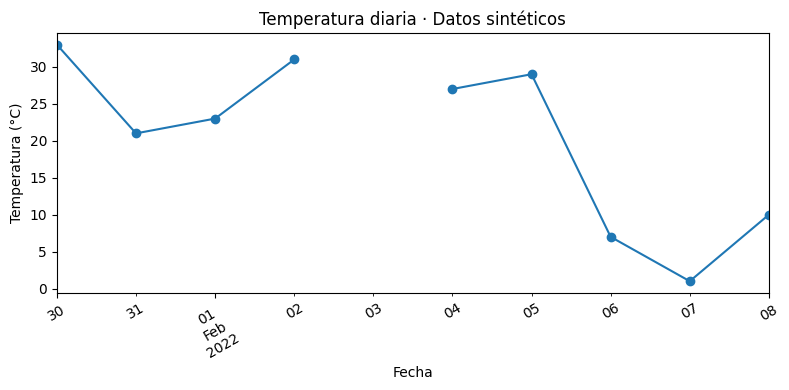

In [59]:
# pandas devuelve un Axes que también puede personalizarse con Matplotlib.
ax = df_serie_temporal["temperatura_C"].plot(
    figsize=(8, 4), marker="o", rot=30,
    title="Temperatura diaria · Datos sintéticos",
    xlabel="Fecha", ylabel="Temperatura (°C)",
)
ax.figure.tight_layout()
plt.show()

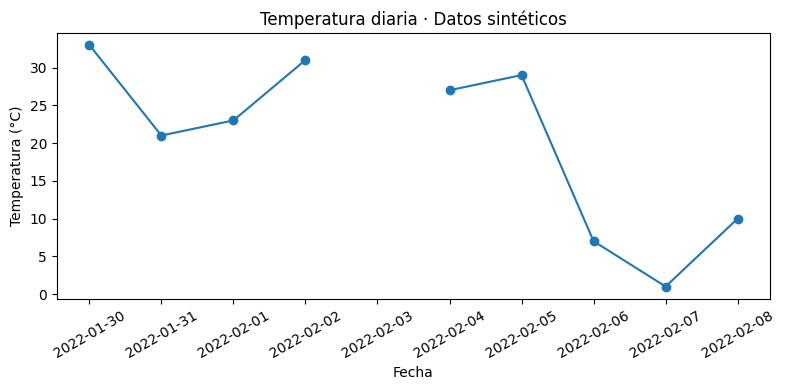

In [60]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(df_serie_temporal.index, df_serie_temporal["temperatura_C"], marker="o")
ax.set(xlabel="Fecha", ylabel="Temperatura (°C)", title="Temperatura diaria · Datos sintéticos")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

### Subgráficos

Cuando dos variables tienen unidades diferentes, es preferible darles ejes verticales separados. Podemos organizar esos ejes en una misma figura mediante **subgráficos**, manteniendo un eje temporal común.

Primero utilizamos `subplots=True` en pandas. Después construimos los dos ejes con Matplotlib y, por último, combinamos ambos enfoques. Representaremos temperatura y precipitación, que son las dos magnitudes disponibles en esta tabla. `sharey=False` evita compartir una escala vertical entre °C y mm.

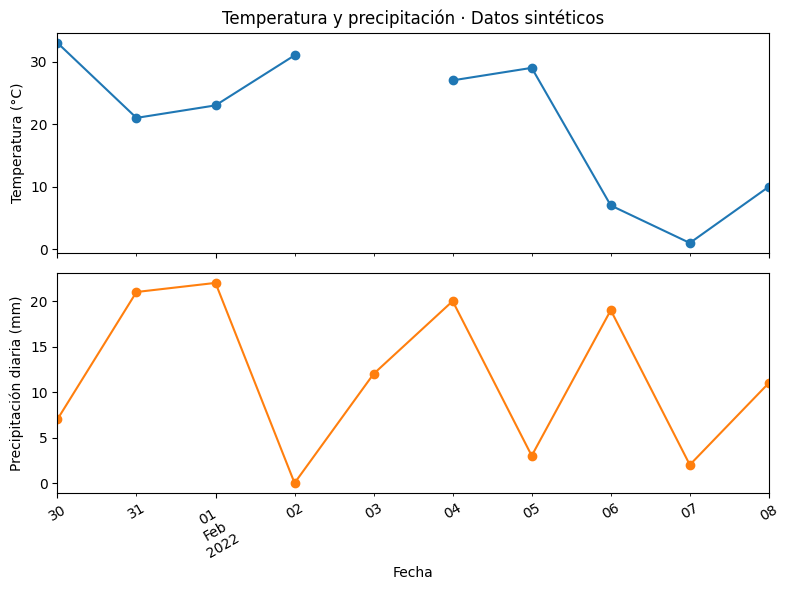

In [61]:
# Cada columna recibe un eje vertical propio; solo se comparte el tiempo.
axes_pandas = df_serie_temporal[["temperatura_C", "precipitacion_mm"]].plot(
    subplots=True, sharex=True, sharey=False, figsize=(8, 6),
    marker="o", legend=False, rot=30,
)
axes_pandas[0].set(title="Temperatura y precipitación · Datos sintéticos", ylabel="Temperatura (°C)")
axes_pandas[1].set(xlabel="Fecha", ylabel="Precipitación diaria (mm)")
axes_pandas[0].figure.tight_layout()
plt.show()

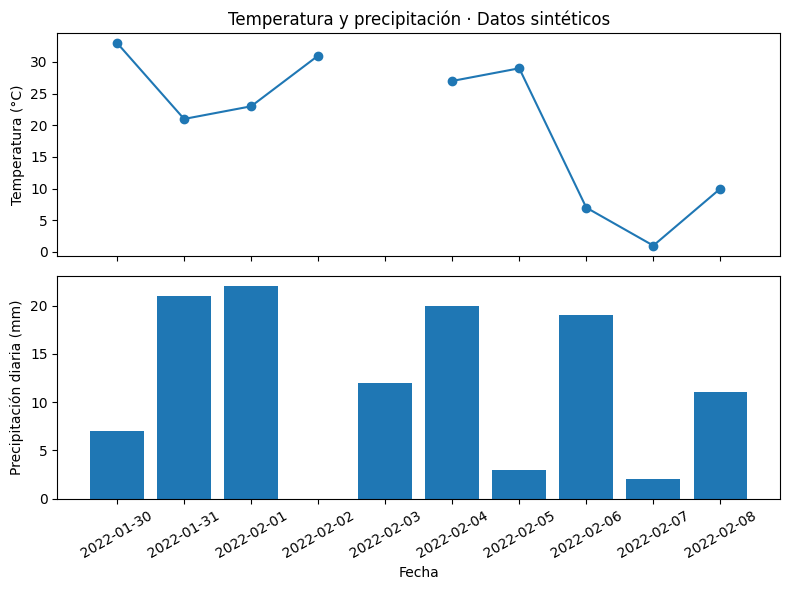

In [62]:
fig, axes_mpl = plt.subplots(2, 1, sharex=True, sharey=False, figsize=(8, 6))
axes_mpl[0].plot(df_serie_temporal.index, df_serie_temporal["temperatura_C"], marker="o")
axes_mpl[0].set(title="Temperatura y precipitación · Datos sintéticos", ylabel="Temperatura (°C)")

# Las barras representan las cantidades de precipitación de cada día.
axes_mpl[1].bar(df_serie_temporal.index, df_serie_temporal["precipitacion_mm"])
axes_mpl[1].set(xlabel="Fecha", ylabel="Precipitación diaria (mm)")
axes_mpl[1].tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

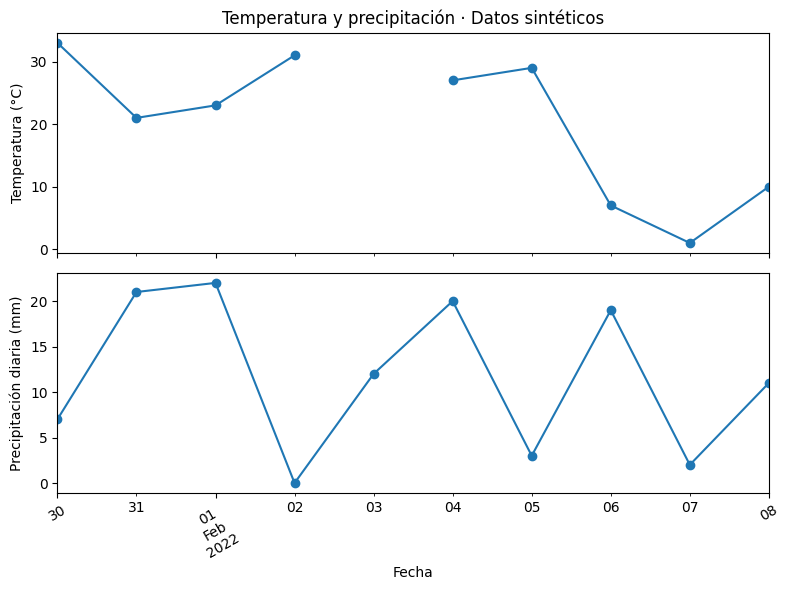

In [63]:
# Creamos los ejes con Matplotlib y trazamos las series mediante pandas.
fig, axes_mixtos = plt.subplots(2, 1, sharex=True, sharey=False, figsize=(8, 6))
df_serie_temporal["temperatura_C"].plot(ax=axes_mixtos[0], marker="o", legend=False)
df_serie_temporal["precipitacion_mm"].plot(ax=axes_mixtos[1], marker="o", legend=False)

axes_mixtos[0].set(title="Temperatura y precipitación · Datos sintéticos", ylabel="Temperatura (°C)")
axes_mixtos[1].set(xlabel="Fecha", ylabel="Precipitación diaria (mm)")
axes_mixtos[1].tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

### Histogramas

Un histograma agrupa los valores en intervalos y cuenta cuántos caen en cada uno. Por defecto representa **frecuencias absolutas**, no una densidad de probabilidad.

Para obtener una densidad se puede utilizar `density=True`; en ese caso el área total de las barras es uno y las unidades del eje vertical son la inversa de las de la variable. Con solo diez días, el ejemplo permite entender la herramienta, pero no caracterizar de forma robusta una distribución climática.

Utilizaremos los mismos intervalos en pandas y Matplotlib para que los dos gráficos sean comparables.

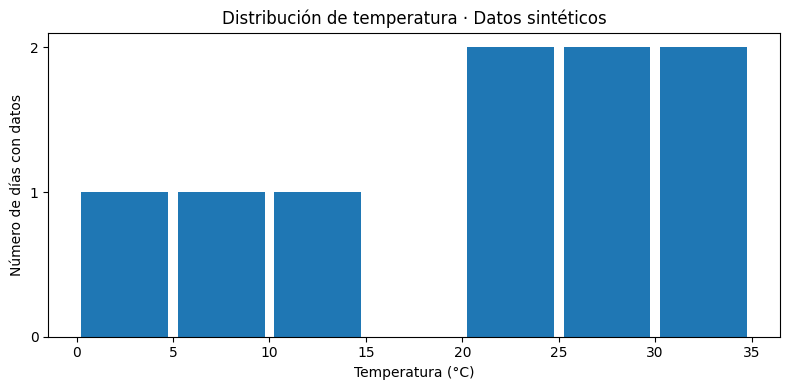

In [64]:
intervalos_temperatura = np.linspace(0, 35, 8)
ax = df_serie_temporal["temperatura_C"].plot.hist(
    bins=intervalos_temperatura, rwidth=0.9, figsize=(8, 4),
    title="Distribución de temperatura · Datos sintéticos",
)
ax.set(xlabel="Temperatura (°C)", ylabel="Número de días con datos")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.figure.tight_layout()
plt.show()

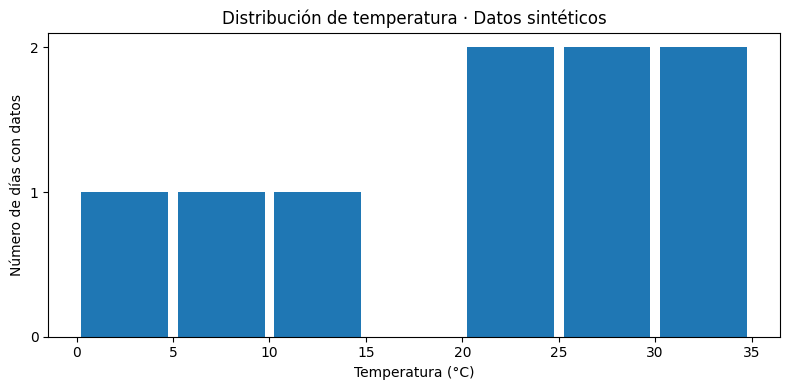

In [65]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df_serie_temporal["temperatura_C"].dropna(), bins=intervalos_temperatura, rwidth=0.9)
ax.set(
    xlabel="Temperatura (°C)", ylabel="Número de días con datos",
    title="Distribución de temperatura · Datos sintéticos",
)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.tight_layout()
plt.show()

### Diagramas de dispersión

Cada punto de un diagrama de dispersión representa un registro con dos valores numéricos. Aquí relacionamos temperatura y precipitación, conservando las parejas de un mismo día y retirando las filas incompletas en cualquiera de esas dos variables.

El gráfico sirve para explorar relaciones, no para establecer causalidad. Como los datos son sintéticos, no debemos atribuir significado físico a una asociación aparente.

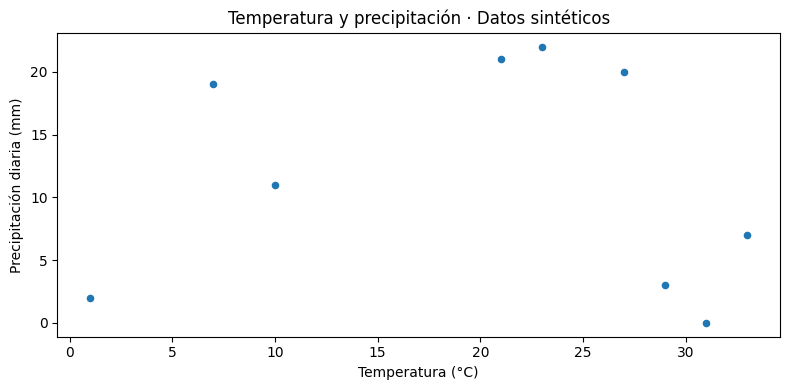

In [66]:
# Ambas variables se filtran juntas para conservar los pares del mismo día.
pares_meteorologicos = df_serie_temporal.dropna(subset=["temperatura_C", "precipitacion_mm"])
ax = pares_meteorologicos.plot.scatter(
    x="temperatura_C", y="precipitacion_mm", figsize=(8, 4),
    title="Temperatura y precipitación · Datos sintéticos",
)
ax.set(xlabel="Temperatura (°C)", ylabel="Precipitación diaria (mm)")
ax.figure.tight_layout()
plt.show()

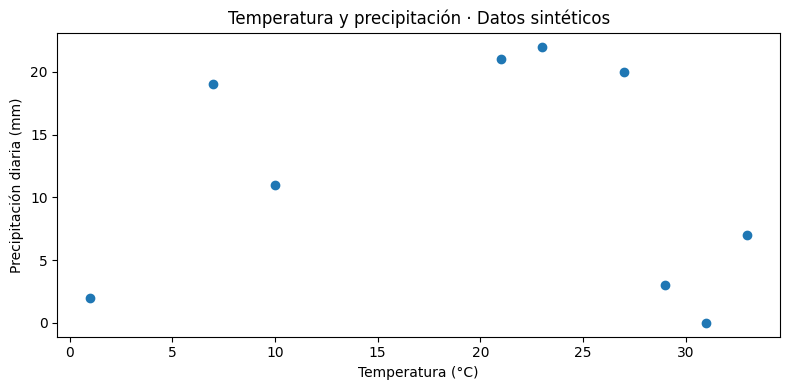

In [67]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(pares_meteorologicos["temperatura_C"], pares_meteorologicos["precipitacion_mm"])
ax.set(
    xlabel="Temperatura (°C)", ylabel="Precipitación diaria (mm)",
    title="Temperatura y precipitación · Datos sintéticos",
)
fig.tight_layout()
plt.show()

### Diagramas de caja

La caja abarca desde el primer cuartil hasta el tercero y su línea interior indica la mediana. Con la configuración predeterminada, los bigotes llegan hasta los valores extremos situados dentro de 1,5 veces el rango intercuartílico desde los bordes de la caja.

Los puntos que quedan fuera se muestran por separado. Son valores alejados según esta regla gráfica, pero no necesariamente errores ni observaciones que deban eliminarse. Con una muestra pequeña, los cuartiles y los bigotes también pueden resultar poco estables.

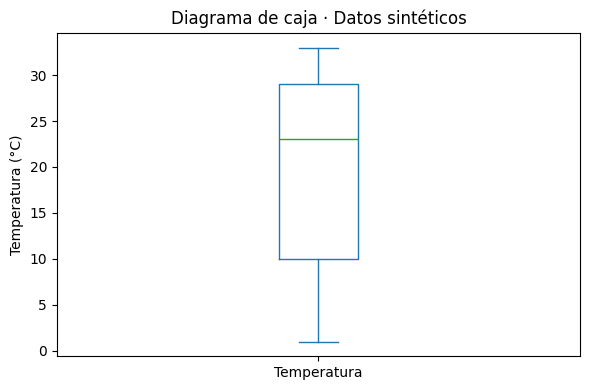

In [68]:
ax = df_serie_temporal[["temperatura_C"]].rename(
    columns={"temperatura_C": "Temperatura"}
).plot.box(figsize=(6, 4))
ax.set(ylabel="Temperatura (°C)", title="Diagrama de caja · Datos sintéticos")
ax.figure.tight_layout()
plt.show()

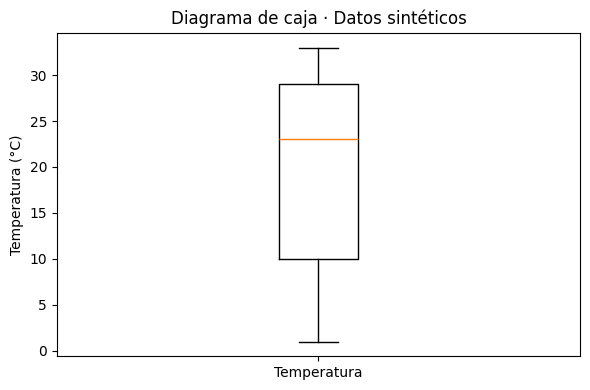

In [69]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(df_serie_temporal["temperatura_C"].dropna())
ax.set_xticks([1], labels=["Temperatura"])
ax.set(ylabel="Temperatura (°C)", title="Diagrama de caja · Datos sintéticos")
fig.tight_layout()
plt.show()